# Sentiment Analysis - Delivery (CISTI Conference)

# Loading Data

In [ ]:
import pandas as pd

df = pd.read_csv('delivery_alimentos.csv')

In [ ]:
df

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,sortOrder,appId
0,0,2cf8d528-4be9-4582-8029-b12c7853ba9c,Daniela Aguilar,https://play-lh.googleusercontent.com/a-/ALV-U...,Fiz um pedido e veio com um item faltando. Ao ...,1,252,9.223.0,2023-09-09 02:48:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood
1,1,a0aefee6-4c2b-4d87-86d6-45ea111dcf50,Arlan Cruz (Miguelito),https://play-lh.googleusercontent.com/a-/ALV-U...,Informações do produto e imagens sem clareza. ...,1,173,9.223.0,2023-09-10 00:24:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood
2,2,4b28558b-23e9-4e14-96b6-6e0e936f1ff1,Gabriel Liondas,https://play-lh.googleusercontent.com/a-/ALV-U...,"Uso o aplicativo a um bom tempo, porém, tive u...",1,12,9.222.1,2023-09-09 16:46:25,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood
3,3,a7d610c9-30aa-4f8b-9a14-142ca9ec3b15,Ester Araújo,https://play-lh.googleusercontent.com/a-/ALV-U...,Não tem mais preocupação com qualidade. Os ent...,1,32,9.221.0,2023-08-31 21:14:46,NaN,NaN,9.221.0,most_relevant,br.com.brainweb.ifood
4,4,9c203cc4-289f-46cf-b55a-6332791b3b8c,Adr_Alv,https://play-lh.googleusercontent.com/a-/ALV-U...,"Não aparece mais cupons, a mais de 7 meses par...",1,14,9.222.1,2023-09-08 14:40:36,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35977,35977,785b13d8-ccc9-4629-b844-557f90d4d734,Lais De Lima,https://play-lh.googleusercontent.com/a/ACg8oc...,Muito bom amei esse app,5,0,10.0.0,2023-07-15 18:45:03,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome
35978,35978,c2121839-7857-49c9-9609-27aed288d297,Marta Silva,https://play-lh.googleusercontent.com/a-/ALV-U...,Muito bom,5,0,10.0.0,2023-07-15 15:56:29,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome
35979,35979,b5286f42-23a0-408c-9fc4-5c0f069e950a,Bp Santos,https://play-lh.googleusercontent.com/a/ACg8oc...,Ótimo pra todo momento www.aiqfome.com,5,0,10.0.0,2023-07-15 03:09:38,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome
35980,35980,b31c7352-1b90-4caf-81d7-e0e2ae9b44d5,Mauro Cesar,https://play-lh.googleusercontent.com/a-/ALV-U...,Top 🤝🏻,5,0,10.0.0,2023-07-15 00:42:34,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome


## Data Analysis

### Checking for Nulls

In [ ]:
def check_nulls():
  number_nulls = df.isnull().sum()
  print(f"Number of nulls per column: {number_nulls}")

In [ ]:
check_nulls()

Number of nulls per column: Unnamed: 0                  0
reviewId                    0
userName                    0
userImage                   0
content                     0
score                       0
thumbsUpCount               0
reviewCreatedVersion     3361
at                          0
replyContent            27020
repliedAt               27020
appVersion               3361
sortOrder                   0
appId                       0
dtype: int64


## Counting words

In [ ]:
type(df['content'].str) # For Pandas Core.String

pandas.core.strings.accessor.StringMethods

In [ ]:
df['word_count'] = df['content'].str.split().apply(len)
df['word_count']

,word_count
0,81
1,77
2,71
3,55
4,95
...,...
35977,5
35978,2
35979,5
35980,2


In [ ]:
df['word_count'].min()

1

In [ ]:
df[df['word_count'] == 1]

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,sortOrder,appId,word_count
344,344,88654cfe-d9ba-40cf-ad94-cecb308bdbae,Isaac Fernandes,https://play-lh.googleusercontent.com/a/ACg8oc...,blz,1,0,9.223.0,2023-09-16 02:37:06,NaN,NaN,9.223.0,newest,br.com.brainweb.ifood,1
350,350,d4e799b2-810f-4bf8-af59-94850c3c7655,Wesley Pereira,https://play-lh.googleusercontent.com/a/ACg8oc...,bom,1,0,9.223.0,2023-09-16 00:42:35,NaN,NaN,9.223.0,newest,br.com.brainweb.ifood,1
396,396,98a94295-64be-4db5-9476-e62cbb370ad3,andré marques gonçalves,https://play-lh.googleusercontent.com/a-/ALV-U...,Lixo,1,0,9.223.0,2023-09-15 00:06:00,NaN,NaN,9.223.0,newest,br.com.brainweb.ifood,1
433,433,dc486f61-7215-4b1f-8ed5-2a7910b497a7,Guthy Oliveira,https://play-lh.googleusercontent.com/a/ACg8oc...,legal,1,0,9.223.0,2023-09-13 23:13:47,NaN,NaN,9.223.0,newest,br.com.brainweb.ifood,1
436,436,d499bfb6-07c1-4412-b201-e738f73df01e,Suzane Gonçalves,https://play-lh.googleusercontent.com/a/ACg8oc...,boa,1,0,9.223.0,2023-09-13 22:51:09,NaN,NaN,9.223.0,newest,br.com.brainweb.ifood,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35944,35944,e88f4128-be1a-48fe-8511-c47e0a218f2a,Elisabeth Michalkiewicz,https://play-lh.googleusercontent.com/a-/ALV-U...,Eficiente,5,0,10.1.0,2023-07-18 20:13:19,NaN,NaN,10.1.0,newest,com.vanuatu.aiqfome,1
35956,35956,1c889bd6-354d-48bc-a46f-49d197f15b46,Miguel Falco,https://play-lh.googleusercontent.com/a-/ALV-U...,🤝🏻,5,0,10.1.0,2023-07-16 23:00:32,NaN,NaN,10.1.0,newest,com.vanuatu.aiqfome,1
35958,35958,26b6009c-7978-404f-a636-d2bd1b373a33,Elizangela dos reis,https://play-lh.googleusercontent.com/a-/ALV-U...,Essepcional,5,0,10.0.0,2023-07-16 21:33:08,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,1
35962,35962,66633f94-1a9d-45b4-b39f-27d2f526e071,Max Evaristo,https://play-lh.googleusercontent.com/a/ACg8oc...,Topzera,5,0,10.0.0,2023-07-16 03:52:00,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,1


In [ ]:
df['word_count'].mean()

np.float64(28.090712022678005)

In [ ]:
df['word_count'].max()

350

<Axes: xlabel='word_count', ylabel='Count'>

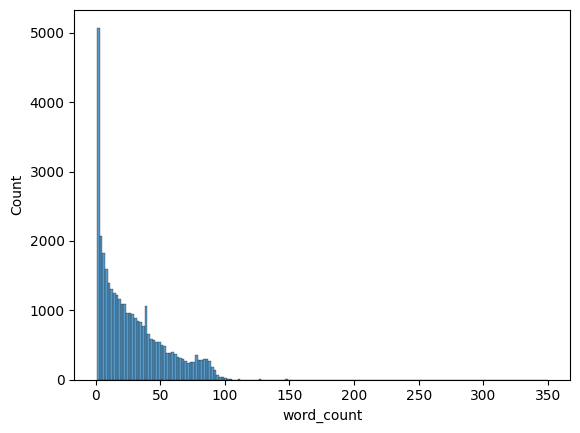

In [ ]:
import seaborn as sns

sns.histplot(df['word_count'])

In [ ]:
import matplotlib.pyplot as plt

def count_words(text_column):
  df['word_count'] = df[text_column].str.split().apply(len)

  min = df['word_count'].min()
  max = df['word_count'].max()
  mean = df['word_count'].mean()

  print(f'The minimum number of words in the dataset is: {min}')
  print(f'The maximum number of words in the dataset is: {max}')
  print(f'The mean number of words in the dataset is: {mean}')

  print('\nHistogram of the number of words')
  sns.histplot(df['word_count'])
  plt.show()

The minimum number of words in the dataset is: 1
The maximum number of words in the dataset is: 350
The mean number of words in the dataset is: 28.090712022678005

Histogram of the number of words


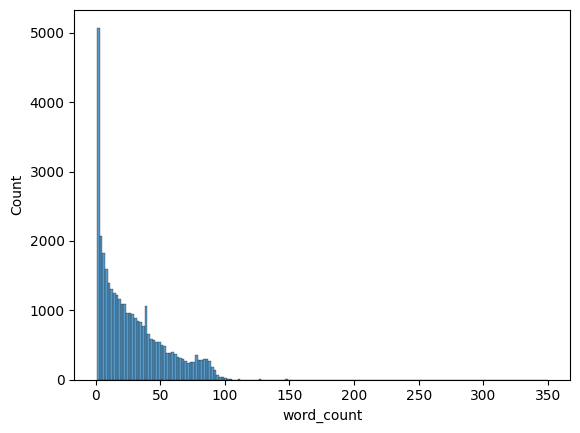

In [ ]:
count_words('content')

## Checking the distribution of scores

In [ ]:
score_counts = df['score'].value_counts()
score_counts

,count
score,
5,9000
4,9000
1,5994
3,5994
2,5994


<Axes: xlabel='score', ylabel='Count'>

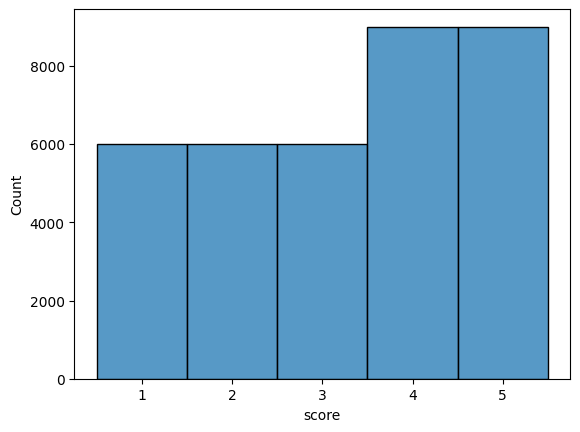

In [ ]:
sns.histplot(df['score'], discrete = True)

In [ ]:
score_counts.index

Index([5, 4, 1, 3, 2], dtype='int64', name='score')

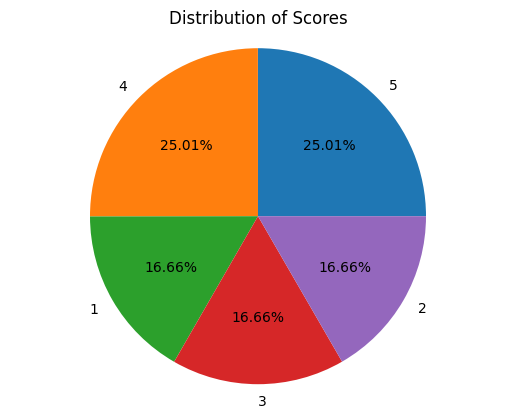

In [ ]:
import matplotlib.pyplot as plt

plt.pie(score_counts, labels = score_counts.index, autopct = '%1.2f%%')
plt.title("Distribution of Scores")
plt.axis("equal")
plt.show;

In [ ]:
def class_distribution(class_column):
  class_counts = df[class_column].value_counts()

  print(f"Number of Instances per Class: {class_counts}")

  print("\nHistogram of the distribution of classes")
  sns.histplot(df[class_column], discrete = True)
  plt.show();

  print("\nPie Chart of the Distribution of Classes")
  plt.pie(class_counts, labels = class_counts.index, autopct = '%1.2f%%')
  plt.title("Distribution of Classes")
  plt.axis("equal")
  plt.show;

Number of Instances per Class: score
5    9000
4    9000
1    5994
3    5994
2    5994
Name: count, dtype: int64

Histogram of the distribution of classes


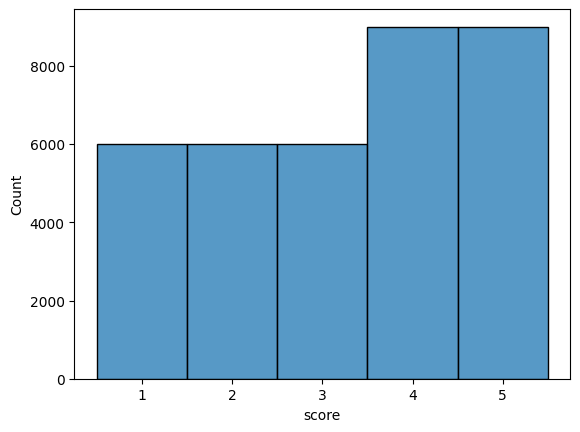


Pie Chart of the Distribution of Classes


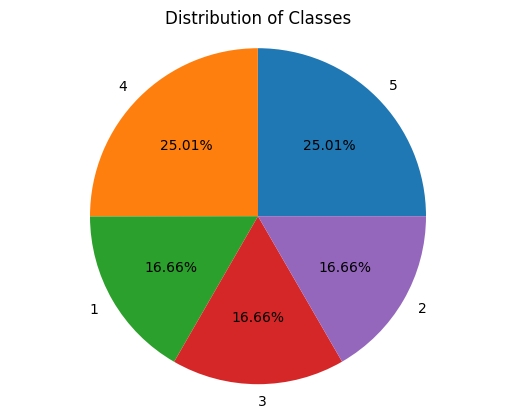

In [ ]:
class_distribution('score')

## Most frequent words
Objective: to find the relevance of each word.

In [ ]:
all_text = ' '.join(df['content'])
all_text

'Fiz um pedido e veio com um item faltando. Ao tentar reportar o erro pelo app na aba "ajuda", quando aperto para finalizar na parte que eles pedem a foto do pedido, ocorre que o app é como se fosse reiniciado e a minha reclamação some, não podendo finalizá-la. Tentei por várias vezes refazer a reclamação e ocorre sempre o mesmo problema, mesmo eu reinstalando o app. Assim, vou ficar no prejuízo por conta do item que não veio no pedido. Informações do produto e imagens sem clareza. A lojas agem e cancelam os pedidos como convier, não respeitam os clientes. Nesses momentos não podemos avaliar as mesmas, e fica sem penalidade. Nos mercados o controle de mercadoria tem um péssimo funcionamento com o app, após a compra muita mercadoria fora do estoque. A logística é falha e morosa. Algumas experiências positivas, mas as negativas foram superiores. É preciso uma seleção mais qualitativa das lojas. Funcionamento atual medíocre. Uso o aplicativo a um bom tempo, porém, tive um problema com meu

In [ ]:
words = all_text.split()
words

['Fiz',
 'um',
 'pedido',
 'e',
 'veio',
 'com',
 'um',
 'item',
 'faltando.',
 'Ao',
 'tentar',
 'reportar',
 'o',
 'erro',
 'pelo',
 'app',
 'na',
 'aba',
 '"ajuda",',
 'quando',
 'aperto',
 'para',
 'finalizar',
 'na',
 'parte',
 'que',
 'eles',
 'pedem',
 'a',
 'foto',
 'do',
 'pedido,',
 'ocorre',
 'que',
 'o',
 'app',
 'é',
 'como',
 'se',
 'fosse',
 'reiniciado',
 'e',
 'a',
 'minha',
 'reclamação',
 'some,',
 'não',
 'podendo',
 'finalizá-la.',
 'Tentei',
 'por',
 'várias',
 'vezes',
 'refazer',
 'a',
 'reclamação',
 'e',
 'ocorre',
 'sempre',
 'o',
 'mesmo',
 'problema,',
 'mesmo',
 'eu',
 'reinstalando',
 'o',
 'app.',
 'Assim,',
 'vou',
 'ficar',
 'no',
 'prejuízo',
 'por',
 'conta',
 'do',
 'item',
 'que',
 'não',
 'veio',
 'no',
 'pedido.',
 'Informações',
 'do',
 'produto',
 'e',
 'imagens',
 'sem',
 'clareza.',
 'A',
 'lojas',
 'agem',
 'e',
 'cancelam',
 'os',
 'pedidos',
 'como',
 'convier,',
 'não',
 'respeitam',
 'os',
 'clientes.',
 'Nesses',
 'momentos',
 'não',
 '

In [ ]:
from collections import Counter

word_count = Counter(words)
print(word_count)

number_words = 10

most_common_words = word_count.most_common(number_words)

Counter({'o': 34379, 'de': 32419, 'e': 30626, 'que': 24527, 'não': 22092, 'a': 19925, 'é': 12873, 'com': 10660, 'do': 10532, 'um': 9547, 'no': 9428, 'para': 8960, 'app': 8677, 'muito': 8151, 'em': 7730, 'mais': 7411, 'tem': 6891, 'mas': 6549, 'pedido': 6352, 'os': 6216, 'na': 6054, 'uma': 5760, 'O': 5750, 'pra': 5141, 'por': 5099, 'da': 4989, 'aplicativo': 4936, 'as': 4399, 'eu': 4370, 'se': 4221, 'meu': 3783, 'só': 3520, 'bom': 3487, 'quando': 3365, 'Não': 3321, 'entrega': 3281, 'pelo': 3051, 'como': 3020, 'foi': 2962, 'já': 2949, 'vezes': 2941, 'opção': 2919, 'ter': 2906, 'me': 2904, 'ou': 2894, 'está': 2887, 'fazer': 2814, 'sempre': 2573, 'sem': 2563, 'minha': 2443, 'ser': 2345, 'App': 2286, 'ao': 2277, 'mesmo': 2267, 'pagamento': 2243, 'isso': 2228, 'bem': 2197, 'cupons': 2128, 'nem': 2074, 'são': 2050, 'cartão': 2041, 'até': 1945, 'consigo': 1935, 'Muito': 1927, 'dos': 1878, 'pois': 1788, 'problema': 1774, 'tive': 1754, 'pagar': 1715, 'A': 1706, 'vez': 1696, 'compra': 1628, 'resta

In [ ]:
most_common_words_df = pd.DataFrame(most_common_words, columns = ['Word','Frequency'])
most_common_words_df

,Word,Frequency
0,o,34379
1,de,32419
2,e,30626
3,que,24527
4,não,22092
5,a,19925
6,é,12873
7,com,10660
8,do,10532
9,um,9547


In [ ]:
def most_frequency_words(df,text_column, number_words):
  all_text = ' '.join(df[text_column])
  words = all_text.split()
  word_count = Counter(words)

  print("\nMost frequent words")
  most_common_words = word_count.most_common(number_words)
  most_common_words_df = pd.DataFrame(most_common_words, columns = ['Word','Frequency'])
  display(most_common_words_df)

In [ ]:
most_frequency_words(df,'content',10)


Most frequent words


,Word,Frequency
0,o,34379
1,de,32419
2,e,30626
3,que,24527
4,não,22092
5,a,19925
6,é,12873
7,com,10660
8,do,10532
9,um,9547


## Most frequent words by class

In [ ]:
df['score'].unique()

array([1, 2, 3, 4, 5])

In [ ]:
for class_label in df['score'].unique():
  class_df = df[df['score'] == class_label]

  print('\nMost frequent words by class', class_label)
  most_frequency_words(class_df, 'content',10)


Most frequent words by class 1

Most frequent words


,Word,Frequency
0,o,8542
1,e,7476
2,de,6939
3,não,6575
4,que,5650
5,a,4309
6,com,2598
7,um,2510
8,no,2379
9,do,2304



Most frequent words by class 2

Most frequent words


,Word,Frequency
0,o,7796
1,de,6708
2,e,6304
3,não,5618
4,que,5422
5,a,4260
6,é,2541
7,com,2266
8,do,2175
9,no,2090



Most frequent words by class 3

Most frequent words


,Word,Frequency
0,o,6622
1,de,6108
2,e,5261
3,que,4784
4,não,4261
5,a,4069
6,é,2659
7,do,2026
8,com,1896
9,no,1882



Most frequent words by class 4

Most frequent words


,Word,Frequency
0,de,7215
1,o,6784
2,e,5794
3,que,5161
4,a,4445
5,não,3844
6,é,3429
7,do,2372
8,muito,2258
9,mais,2037



Most frequent words by class 5

Most frequent words


,Word,Frequency
0,e,5791
1,de,5449
2,o,4635
3,que,3510
4,a,2842
5,muito,2435
6,é,2119
7,com,1903
8,não,1794
9,do,1655


In [ ]:
def most_frequency_words_by_class(text_column, class_column):
  for class_label in df[class_column].unique():
    class_df = df[df[class_column] == class_label]

    print('\nMost frequent words by class', class_label)
    most_frequency_words(class_df, text_column ,10)

In [ ]:
most_frequency_words_by_class('content', 'score')


Most frequent words by class 1

Most frequent words


,Word,Frequency
0,o,8542
1,e,7476
2,de,6939
3,não,6575
4,que,5650
5,a,4309
6,com,2598
7,um,2510
8,no,2379
9,do,2304



Most frequent words by class 2

Most frequent words


,Word,Frequency
0,o,7796
1,de,6708
2,e,6304
3,não,5618
4,que,5422
5,a,4260
6,é,2541
7,com,2266
8,do,2175
9,no,2090



Most frequent words by class 3

Most frequent words


,Word,Frequency
0,o,6622
1,de,6108
2,e,5261
3,que,4784
4,não,4261
5,a,4069
6,é,2659
7,do,2026
8,com,1896
9,no,1882



Most frequent words by class 4

Most frequent words


,Word,Frequency
0,de,7215
1,o,6784
2,e,5794
3,que,5161
4,a,4445
5,não,3844
6,é,3429
7,do,2372
8,muito,2258
9,mais,2037



Most frequent words by class 5

Most frequent words


,Word,Frequency
0,e,5791
1,de,5449
2,o,4635
3,que,3510
4,a,2842
5,muito,2435
6,é,2119
7,com,1903
8,não,1794
9,do,1655


## WordCloud
Quick visualization of word frequency

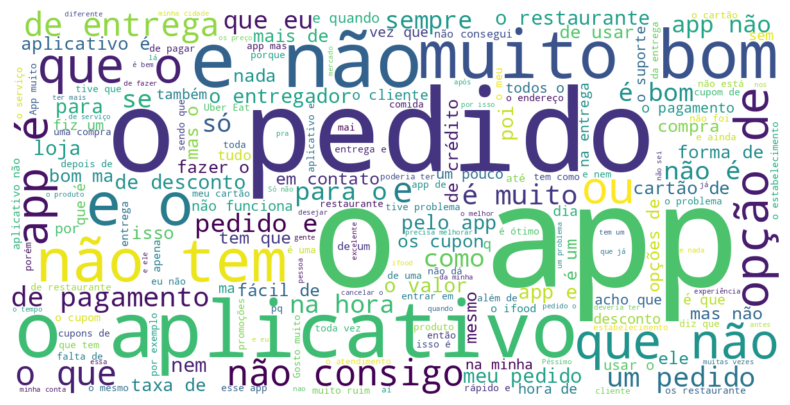

In [ ]:
from wordcloud import WordCloud

all_text = ' '.join(df['content'])

wordcloud = WordCloud(width = 1200, height = 600, background_color = 'white').generate(all_text)

plt.figure(figsize = (10,5))
plt.imshow(wordcloud, interpolation = 'bilinear')
plt.axis('off')
plt.show()

In [ ]:
def word_cloud(text_column):
  all_text = ' '.join(df[text_column])

  print('\nWordCloud')
  wordcloud = WordCloud(width = 1200, height = 600, background_color = 'black').generate(all_text)

  plt.figure(figsize = (10,5))
  plt.imshow(wordcloud, interpolation = 'bilinear')
  plt.axis('off')
  plt.show()


WordCloud


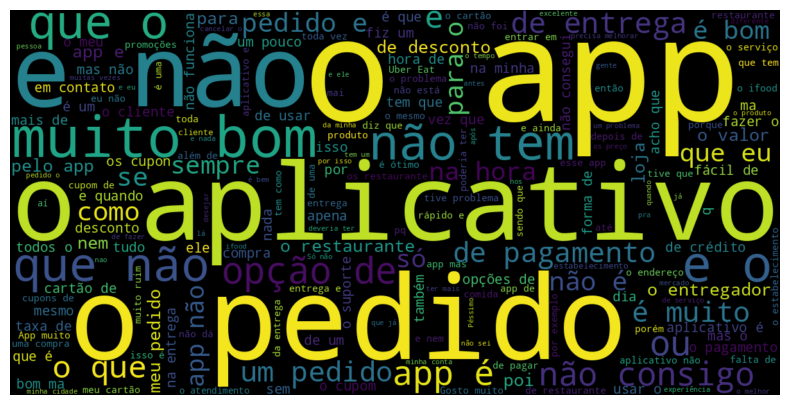

In [ ]:
word_cloud('content')

## Combining all data analysis functions

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud

def data_analytics(df,text_column,class_column ):
  check_nulls()
  count_words(text_column)
  class_distribution(class_column)
  most_frequency_words(df,text_column, number_words)
  most_frequency_words_by_class(text_column, class_column)
  word_cloud(text_column)

Number of nulls per column: Unnamed: 0                  0
reviewId                    0
userName                    0
userImage                   0
content                     0
score                       0
thumbsUpCount               0
reviewCreatedVersion     3361
at                          0
replyContent            27020
repliedAt               27020
appVersion               3361
sortOrder                   0
appId                       0
word_count                  0
dtype: int64
The minimum number of words in the dataset is: 1
The maximum number of words in the dataset is: 350
The mean number of words in the dataset is: 28.090712022678005

Histogram of the number of words


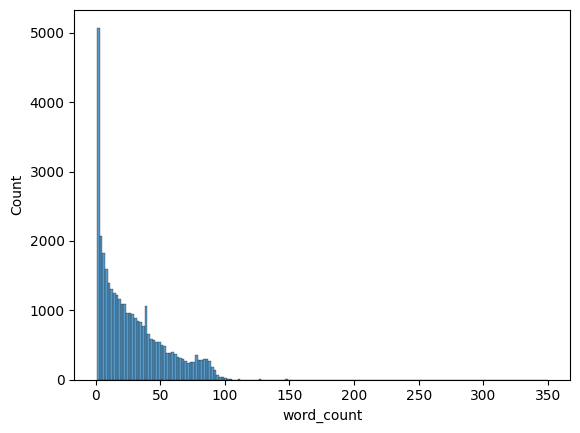

Number of Instances per Class: score
5    9000
4    9000
1    5994
3    5994
2    5994
Name: count, dtype: int64

Histogram of the distribution of classes


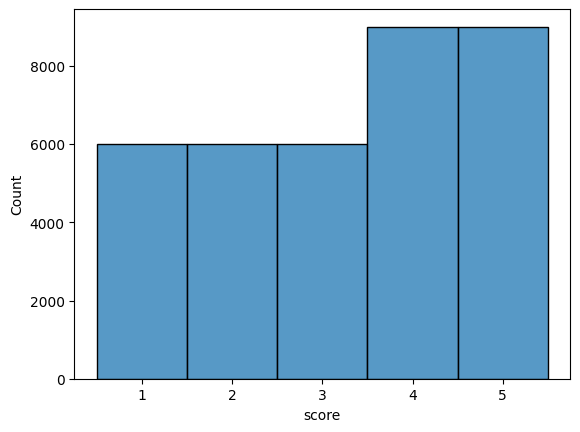


Pie Chart of the Distribution of Classes

Most frequent words


,Word,Frequency
0,o,34379
1,de,32419
2,e,30626
3,que,24527
4,não,22092
5,a,19925
6,é,12873
7,com,10660
8,do,10532
9,um,9547



Most frequent words by class 1

Most frequent words


,Word,Frequency
0,o,8542
1,e,7476
2,de,6939
3,não,6575
4,que,5650
5,a,4309
6,com,2598
7,um,2510
8,no,2379
9,do,2304



Most frequent words by class 2

Most frequent words


...


Most frequent words by class 4

Most frequent words


,Word,Frequency
0,de,7215
1,o,6784
2,e,5794
3,que,5161
4,a,4445
5,não,3844
6,é,3429
7,do,2372
8,muito,2258
9,mais,2037



Most frequent words by class 5

Most frequent words


,Word,Frequency
0,e,5791
1,de,5449
2,o,4635
3,que,3510
4,a,2842
5,muito,2435
6,é,2119
7,com,1903
8,não,1794
9,do,1655



WordCloud


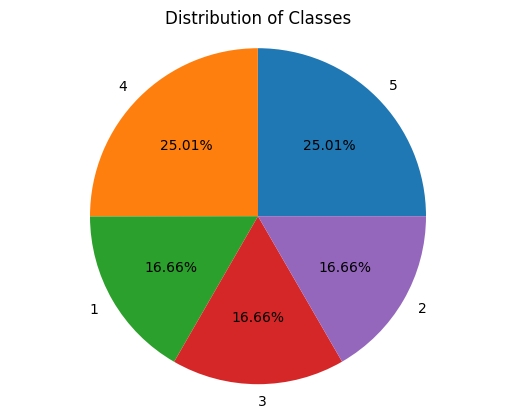

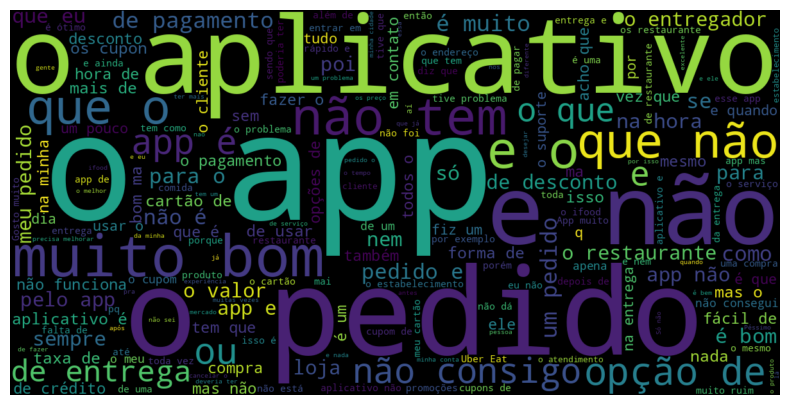

In [ ]:
data_analytics(df, 'content', 'score')

# Preprocessing


## Removing Emojis


In [ ]:
import re

def remove_emojis(text):
  emoji_pattern = re.compile("["
                            u"\U0001F600-\U0001F64F"
                            u"\U0001F300-\U0001F5FF"
                            u"\U0001F600-\U0001F6FF"
                            u"\U0001F700-\U0001F77F"
                            u"\U0001F780-\U0001F7FF"
                            u"\U0001F800-\U0001F8FF"
                            u"\U0001F900-\U0001F9FF"
                            u"\U0001FA00-\U0001FA6F"
                            u"\U0001FA70-\U0001FAFF"
                            u"\U0001F004"
                            u"\U0001F0CF"
                            u"\U0001F170-\U0001F251"
                            u"\U00002702-\U00002780"
                            u"\U000024C2-\U0001F251"
                              "]+", flags = re.UNICODE)
  return emoji_pattern.sub(r' ', text)

df['removed_emoji'] = df['content'].apply(remove_emojis)

## Removing Links

In [ ]:
def remove_link(text):
  text_without_links = re.sub(r'www\S+|http\S+|ftp\S+', '', text)
  return text_without_links

df['removed_links'] = df['removed_emoji'].apply(remove_link)

df

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,sortOrder,appId,word_count,removed_emoji,removed_links
0,0,2cf8d528-4be9-4582-8029-b12c7853ba9c,Daniela Aguilar,https://play-lh.googleusercontent.com/a-/ALV-U...,Fiz um pedido e veio com um item faltando. Ao ...,1,252,9.223.0,2023-09-09 02:48:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood,81,Fiz um pedido e veio com um item faltando. Ao ...,Fiz um pedido e veio com um item faltando. Ao ...
1,1,a0aefee6-4c2b-4d87-86d6-45ea111dcf50,Arlan Cruz (Miguelito),https://play-lh.googleusercontent.com/a-/ALV-U...,Informações do produto e imagens sem clareza. ...,1,173,9.223.0,2023-09-10 00:24:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood,77,Informações do produto e imagens sem clareza. ...,Informações do produto e imagens sem clareza. ...
2,2,4b28558b-23e9-4e14-96b6-6e0e936f1ff1,Gabriel Liondas,https://play-lh.googleusercontent.com/a-/ALV-U...,"Uso o aplicativo a um bom tempo, porém, tive u...",1,12,9.222.1,2023-09-09 16:46:25,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood,71,"Uso o aplicativo a um bom tempo, porém, tive u...","Uso o aplicativo a um bom tempo, porém, tive u..."
3,3,a7d610c9-30aa-4f8b-9a14-142ca9ec3b15,Ester Araújo,https://play-lh.googleusercontent.com/a-/ALV-U...,Não tem mais preocupação com qualidade. Os ent...,1,32,9.221.0,2023-08-31 21:14:46,NaN,NaN,9.221.0,most_relevant,br.com.brainweb.ifood,55,Não tem mais preocupação com qualidade. Os ent...,Não tem mais preocupação com qualidade. Os ent...
4,4,9c203cc4-289f-46cf-b55a-6332791b3b8c,Adr_Alv,https://play-lh.googleusercontent.com/a-/ALV-U...,"Não aparece mais cupons, a mais de 7 meses par...",1,14,9.222.1,2023-09-08 14:40:36,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood,95,"Não aparece mais cupons, a mais de 7 meses par...","Não aparece mais cupons, a mais de 7 meses par..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35977,35977,785b13d8-ccc9-4629-b844-557f90d4d734,Lais De Lima,https://play-lh.googleusercontent.com/a/ACg8oc...,Muito bom amei esse app,5,0,10.0.0,2023-07-15 18:45:03,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,5,Muito bom amei esse app,Muito bom amei esse app
35978,35978,c2121839-7857-49c9-9609-27aed288d297,Marta Silva,https://play-lh.googleusercontent.com/a-/ALV-U...,Muito bom,5,0,10.0.0,2023-07-15 15:56:29,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,2,Muito bom,Muito bom
35979,35979,b5286f42-23a0-408c-9fc4-5c0f069e950a,Bp Santos,https://play-lh.googleusercontent.com/a/ACg8oc...,Ótimo pra todo momento www.aiqfome.com,5,0,10.0.0,2023-07-15 03:09:38,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,5,Ótimo pra todo momento www.aiqfome.com,Ótimo pra todo momento
35980,35980,b31c7352-1b90-4caf-81d7-e0e2ae9b44d5,Mauro Cesar,https://play-lh.googleusercontent.com/a-/ALV-U...,Top 🤝🏻,5,0,10.0.0,2023-07-15 00:42:34,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,2,Top,Top


## Tokenization

In [ ]:
import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')

def tokenize_text(text):
  tokens = word_tokenize(text)
  return tokens

df['tokens'] = df['removed_links'].apply(tokenize_text)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
df

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,sortOrder,appId,word_count,removed_emoji,removed_links,tokens
0,0,2cf8d528-4be9-4582-8029-b12c7853ba9c,Daniela Aguilar,https://play-lh.googleusercontent.com/a-/ALV-U...,Fiz um pedido e veio com um item faltando. Ao ...,1,252,9.223.0,2023-09-09 02:48:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood,81,Fiz um pedido e veio com um item faltando. Ao ...,Fiz um pedido e veio com um item faltando. Ao ...,"[Fiz, um, pedido, e, veio, com, um, item, falt..."
1,1,a0aefee6-4c2b-4d87-86d6-45ea111dcf50,Arlan Cruz (Miguelito),https://play-lh.googleusercontent.com/a-/ALV-U...,Informações do produto e imagens sem clareza. ...,1,173,9.223.0,2023-09-10 00:24:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood,77,Informações do produto e imagens sem clareza. ...,Informações do produto e imagens sem clareza. ...,"[Informações, do, produto, e, imagens, sem, cl..."
2,2,4b28558b-23e9-4e14-96b6-6e0e936f1ff1,Gabriel Liondas,https://play-lh.googleusercontent.com/a-/ALV-U...,"Uso o aplicativo a um bom tempo, porém, tive u...",1,12,9.222.1,2023-09-09 16:46:25,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood,71,"Uso o aplicativo a um bom tempo, porém, tive u...","Uso o aplicativo a um bom tempo, porém, tive u...","[Uso, o, aplicativo, a, um, bom, tempo, ,, por..."
3,3,a7d610c9-30aa-4f8b-9a14-142ca9ec3b15,Ester Araújo,https://play-lh.googleusercontent.com/a-/ALV-U...,Não tem mais preocupação com qualidade. Os ent...,1,32,9.221.0,2023-08-31 21:14:46,NaN,NaN,9.221.0,most_relevant,br.com.brainweb.ifood,55,Não tem mais preocupação com qualidade. Os ent...,Não tem mais preocupação com qualidade. Os ent...,"[Não, tem, mais, preocupação, com, qualidade, ..."
4,4,9c203cc4-289f-46cf-b55a-6332791b3b8c,Adr_Alv,https://play-lh.googleusercontent.com/a-/ALV-U...,"Não aparece mais cupons, a mais de 7 meses par...",1,14,9.222.1,2023-09-08 14:40:36,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood,95,"Não aparece mais cupons, a mais de 7 meses par...","Não aparece mais cupons, a mais de 7 meses par...","[Não, aparece, mais, cupons, ,, a, mais, de, 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35977,35977,785b13d8-ccc9-4629-b844-557f90d4d734,Lais De Lima,https://play-lh.googleusercontent.com/a/ACg8oc...,Muito bom amei esse app,5,0,10.0.0,2023-07-15 18:45:03,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,5,Muito bom amei esse app,Muito bom amei esse app,"[Muito, bom, amei, esse, app]"
35978,35978,c2121839-7857-49c9-9609-27aed288d297,Marta Silva,https://play-lh.googleusercontent.com/a-/ALV-U...,Muito bom,5,0,10.0.0,2023-07-15 15:56:29,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,2,Muito bom,Muito bom,"[Muito, bom]"
35979,35979,b5286f42-23a0-408c-9fc4-5c0f069e950a,Bp Santos,https://play-lh.googleusercontent.com/a/ACg8oc...,Ótimo pra todo momento www.aiqfome.com,5,0,10.0.0,2023-07-15 03:09:38,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,5,Ótimo pra todo momento www.aiqfome.com,Ótimo pra todo momento,"[Ótimo, pra, todo, momento]"
35980,35980,b31c7352-1b90-4caf-81d7-e0e2ae9b44d5,Mauro Cesar,https://play-lh.googleusercontent.com/a-/ALV-U...,Top 🤝🏻,5,0,10.0.0,2023-07-15 00:42:34,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,2,Top,Top,[Top]


## Converting to lowercase

In [ ]:
def lowercase(tokens):
  lowercase_tokens = [token.lower() for token in tokens]
  return lowercase_tokens

df['tokens_lowercase'] = df['tokens'].apply(lowercase)

In [ ]:
df

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,sortOrder,appId,word_count,removed_emoji,removed_links,tokens,tokens_lowercase
0,0,2cf8d528-4be9-4582-8029-b12c7853ba9c,Daniela Aguilar,https://play-lh.googleusercontent.com/a-/ALV-U...,Fiz um pedido e veio com um item faltando. Ao ...,1,252,9.223.0,2023-09-09 02:48:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood,81,Fiz um pedido e veio com um item faltando. Ao ...,Fiz um pedido e veio com um item faltando. Ao ...,"[Fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt..."
1,1,a0aefee6-4c2b-4d87-86d6-45ea111dcf50,Arlan Cruz (Miguelito),https://play-lh.googleusercontent.com/a-/ALV-U...,Informações do produto e imagens sem clareza. ...,1,173,9.223.0,2023-09-10 00:24:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood,77,Informações do produto e imagens sem clareza. ...,Informações do produto e imagens sem clareza. ...,"[Informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl..."
2,2,4b28558b-23e9-4e14-96b6-6e0e936f1ff1,Gabriel Liondas,https://play-lh.googleusercontent.com/a-/ALV-U...,"Uso o aplicativo a um bom tempo, porém, tive u...",1,12,9.222.1,2023-09-09 16:46:25,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood,71,"Uso o aplicativo a um bom tempo, porém, tive u...","Uso o aplicativo a um bom tempo, porém, tive u...","[Uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, ,, por..."
3,3,a7d610c9-30aa-4f8b-9a14-142ca9ec3b15,Ester Araújo,https://play-lh.googleusercontent.com/a-/ALV-U...,Não tem mais preocupação com qualidade. Os ent...,1,32,9.221.0,2023-08-31 21:14:46,NaN,NaN,9.221.0,most_relevant,br.com.brainweb.ifood,55,Não tem mais preocupação com qualidade. Os ent...,Não tem mais preocupação com qualidade. Os ent...,"[Não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ..."
4,4,9c203cc4-289f-46cf-b55a-6332791b3b8c,Adr_Alv,https://play-lh.googleusercontent.com/a-/ALV-U...,"Não aparece mais cupons, a mais de 7 meses par...",1,14,9.222.1,2023-09-08 14:40:36,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood,95,"Não aparece mais cupons, a mais de 7 meses par...","Não aparece mais cupons, a mais de 7 meses par...","[Não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, ,, a, mais, de, 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35977,35977,785b13d8-ccc9-4629-b844-557f90d4d734,Lais De Lima,https://play-lh.googleusercontent.com/a/ACg8oc...,Muito bom amei esse app,5,0,10.0.0,2023-07-15 18:45:03,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,5,Muito bom amei esse app,Muito bom amei esse app,"[Muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]"
35978,35978,c2121839-7857-49c9-9609-27aed288d297,Marta Silva,https://play-lh.googleusercontent.com/a-/ALV-U...,Muito bom,5,0,10.0.0,2023-07-15 15:56:29,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,2,Muito bom,Muito bom,"[Muito, bom]","[muito, bom]"
35979,35979,b5286f42-23a0-408c-9fc4-5c0f069e950a,Bp Santos,https://play-lh.googleusercontent.com/a/ACg8oc...,Ótimo pra todo momento www.aiqfome.com,5,0,10.0.0,2023-07-15 03:09:38,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,5,Ótimo pra todo momento www.aiqfome.com,Ótimo pra todo momento,"[Ótimo, pra, todo, momento]","[ótimo, pra, todo, momento]"
35980,35980,b31c7352-1b90-4caf-81d7-e0e2ae9b44d5,Mauro Cesar,https://play-lh.googleusercontent.com/a-/ALV-U...,Top 🤝🏻,5,0,10.0.0,2023-07-15 00:42:34,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,2,Top,Top,[Top],[top]


## Removing Punctuation

In [ ]:
import string

string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [ ]:
def remove_punctuation(tokens):
  tokens_without_punctuation = [token for token in tokens if token not in string.punctuation]
  return tokens_without_punctuation

df['tokens_without_punctuation'] = df['tokens_lowercase'].apply(remove_punctuation)

df

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,sortOrder,appId,word_count,removed_emoji,removed_links,tokens,tokens_lowercase,tokens_without_punctuation
0,0,2cf8d528-4be9-4582-8029-b12c7853ba9c,Daniela Aguilar,https://play-lh.googleusercontent.com/a-/ALV-U...,Fiz um pedido e veio com um item faltando. Ao ...,1,252,9.223.0,2023-09-09 02:48:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood,81,Fiz um pedido e veio com um item faltando. Ao ...,Fiz um pedido e veio com um item faltando. Ao ...,"[Fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt..."
1,1,a0aefee6-4c2b-4d87-86d6-45ea111dcf50,Arlan Cruz (Miguelito),https://play-lh.googleusercontent.com/a-/ALV-U...,Informações do produto e imagens sem clareza. ...,1,173,9.223.0,2023-09-10 00:24:00,NaN,NaN,9.223.0,most_relevant,br.com.brainweb.ifood,77,Informações do produto e imagens sem clareza. ...,Informações do produto e imagens sem clareza. ...,"[Informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl..."
2,2,4b28558b-23e9-4e14-96b6-6e0e936f1ff1,Gabriel Liondas,https://play-lh.googleusercontent.com/a-/ALV-U...,"Uso o aplicativo a um bom tempo, porém, tive u...",1,12,9.222.1,2023-09-09 16:46:25,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood,71,"Uso o aplicativo a um bom tempo, porém, tive u...","Uso o aplicativo a um bom tempo, porém, tive u...","[Uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, porém,..."
3,3,a7d610c9-30aa-4f8b-9a14-142ca9ec3b15,Ester Araújo,https://play-lh.googleusercontent.com/a-/ALV-U...,Não tem mais preocupação com qualidade. Os ent...,1,32,9.221.0,2023-08-31 21:14:46,NaN,NaN,9.221.0,most_relevant,br.com.brainweb.ifood,55,Não tem mais preocupação com qualidade. Os ent...,Não tem mais preocupação com qualidade. Os ent...,"[Não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ..."
4,4,9c203cc4-289f-46cf-b55a-6332791b3b8c,Adr_Alv,https://play-lh.googleusercontent.com/a-/ALV-U...,"Não aparece mais cupons, a mais de 7 meses par...",1,14,9.222.1,2023-09-08 14:40:36,NaN,NaN,9.222.1,most_relevant,br.com.brainweb.ifood,95,"Não aparece mais cupons, a mais de 7 meses par...","Não aparece mais cupons, a mais de 7 meses par...","[Não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, a, mais, de, 7, m..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35977,35977,785b13d8-ccc9-4629-b844-557f90d4d734,Lais De Lima,https://play-lh.googleusercontent.com/a/ACg8oc...,Muito bom amei esse app,5,0,10.0.0,2023-07-15 18:45:03,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,5,Muito bom amei esse app,Muito bom amei esse app,"[Muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]"
35978,35978,c2121839-7857-49c9-9609-27aed288d297,Marta Silva,https://play-lh.googleusercontent.com/a-/ALV-U...,Muito bom,5,0,10.0.0,2023-07-15 15:56:29,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,2,Muito bom,Muito bom,"[Muito, bom]","[muito, bom]","[muito, bom]"
35979,35979,b5286f42-23a0-408c-9fc4-5c0f069e950a,Bp Santos,https://play-lh.googleusercontent.com/a/ACg8oc...,Ótimo pra todo momento www.aiqfome.com,5,0,10.0.0,2023-07-15 03:09:38,NaN,NaN,10.0.0,newest,com.vanuatu.aiqfome,5,Ótimo pra todo momento www.aiqfome.com,Ótimo pra todo momento,"[Ótimo, pra, todo, momento]","[ótimo, pra, todo, momento]","[ótimo, pra, todo, momento]"
35980,35980,b31c7352-1b90-4caf-81d7-e0e2ae9b44d5,Mauro Cesar,https://play-lh.googleusercontent.com/a-/ALV-U...,Top 🤝🏻,5,0,10.0.0,2023-07-15 00:42:34,NaN,NaN,10.0.0,newest,com.van

## StopWords

In [ ]:
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = stopwords.words('portuguese')
stop_words

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


['a',
 'à',
 'ao',
 'aos',
 'aquela',
 'aquelas',
 'aquele',
 'aqueles',
 'aquilo',
 'as',
 'às',
 'até',
 'com',
 'como',
 'da',
 'das',
 'de',
 'dela',
 'delas',
 'dele',
 'deles',
 'depois',
 'do',
 'dos',
 'e',
 'é',
 'ela',
 'elas',
 'ele',
 'eles',
 'em',
 'entre',
 'era',
 'eram',
 'éramos',
 'essa',
 'essas',
 'esse',
 'esses',
 'esta',
 'está',
 'estamos',
 'estão',
 'estar',
 'estas',
 'estava',
 'estavam',
 'estávamos',
 'este',
 'esteja',
 'estejam',
 'estejamos',
 'estes',
 'esteve',
 'estive',
 'estivemos',
 'estiver',
 'estivera',
 'estiveram',
 'estivéramos',
 'estiverem',
 'estivermos',
 'estivesse',
 'estivessem',
 'estivéssemos',
 'estou',
 'eu',
 'foi',
 'fomos',
 'for',
 'fora',
 'foram',
 'fôramos',
 'forem',
 'formos',
 'fosse',
 'fossem',
 'fôssemos',
 'fui',
 'há',
 'haja',
 'hajam',
 'hajamos',
 'hão',
 'havemos',
 'haver',
 'hei',
 'houve',
 'houvemos',
 'houver',
 'houvera',
 'houverá',
 'houveram',
 'houvéramos',
 'houverão',
 'houverei',
 'houverem',
 'hou

In [ ]:
len(stop_words)

208

In [ ]:
def remove_stopwords(tokens):
  tokens_without_stopwords = [token for token in tokens if token not in stop_words]
  return tokens_without_stopwords

df['tokens_without_stopwords'] = df['tokens_without_punctuation'].apply(remove_stopwords)

In [ ]:
df

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,...,appVersion,sortOrder,appId,word_count,removed_emoji,removed_links,tokens,tokens_lowercase,tokens_without_punctuation,tokens_without_stopwords
0,0,2cf8d528-4be9-4582-8029-b12c7853ba9c,Daniela Aguilar,https://play-lh.googleusercontent.com/a-/ALV-U...,Fiz um pedido e veio com um item faltando. Ao ...,1,252,9.223.0,2023-09-09 02:48:00,NaN,...,9.223.0,most_relevant,br.com.brainweb.ifood,81,Fiz um pedido e veio com um item faltando. Ao ...,Fiz um pedido e veio com um item faltando. Ao ...,"[Fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, pedido, veio, item, faltando, tentar, re..."
1,1,a0aefee6-4c2b-4d87-86d6-45ea111dcf50,Arlan Cruz (Miguelito),https://play-lh.googleusercontent.com/a-/ALV-U...,Informações do produto e imagens sem clareza. ...,1,173,9.223.0,2023-09-10 00:24:00,NaN,...,9.223.0,most_relevant,br.com.brainweb.ifood,77,Informações do produto e imagens sem clareza. ...,Informações do produto e imagens sem clareza. ...,"[Informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl...","[informações, produto, imagens, clareza, lojas..."
2,2,4b28558b-23e9-4e14-96b6-6e0e936f1ff1,Gabriel Liondas,https://play-lh.googleusercontent.com/a-/ALV-U...,"Uso o aplicativo a um bom tempo, porém, tive u...",1,12,9.222.1,2023-09-09 16:46:25,NaN,...,9.222.1,most_relevant,br.com.brainweb.ifood,71,"Uso o aplicativo a um bom tempo, porém, tive u...","Uso o aplicativo a um bom tempo, porém, tive u...","[Uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, porém,...","[uso, aplicativo, bom, tempo, porém, problema,..."
3,3,a7d610c9-30aa-4f8b-9a14-142ca9ec3b15,Ester Araújo,https://play-lh.googleusercontent.com/a-/ALV-U...,Não tem mais preocupação com qualidade. Os ent...,1,32,9.221.0,2023-08-31 21:14:46,NaN,...,9.221.0,most_relevant,br.com.brainweb.ifood,55,Não tem mais preocupação com qualidade. Os ent...,Não tem mais preocupação com qualidade. Os ent...,"[Não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ...","[preocupação, qualidade, entregadores, atrasam..."
4,4,9c203cc4-289f-46cf-b55a-6332791b3b8c,Adr_Alv,https://play-lh.googleusercontent.com/a-/ALV-U...,"Não aparece mais cupons, a mais de 7 meses par...",1,14,9.222.1,2023-09-08 14:40:36,NaN,...,9.222.1,most_relevant,br.com.brainweb.ifood,95,"Não aparece mais cupons, a mais de 7 meses par...","Não aparece mais cupons, a mais de 7 meses par...","[Não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, a, mais, de, 7, m...","[aparece, cupons, 7, meses, específico, restau..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35977,35977,785b13d8-ccc9-4629-b844-557f90d4d734,Lais De Lima,https://play-lh.googleusercontent.com/a/ACg8oc...,Muito bom amei esse app,5,0,10.0.0,2023-07-15 18:45:03,NaN,...,10.0.0,newest,com.vanuatu.aiqfome,5,Muito bom amei esse app,Muito bom amei esse app,"[Muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]","[bom, amei]"
35978,35978,c2121839-7857-49c9-9609-27aed288d297,Marta Silva,https://play-lh.googleusercontent.com/a-/ALV-U...,Muito bom,5,0,10.0.0,2023-07-15 15:56:29,NaN,...,10.0.0,newest,com.vanuatu.aiqfome,2,Muito bom,Muito bom,"[Muito, bom]","[muito, bom]","[muito, bom]",[bom]
35979,35979,b5286f42-23a0-408c-9fc4-5c0f069e950a,Bp Santos,https://play-lh.googleusercontent.com/a/ACg8oc...,Ótimo pra todo momento www.aiqfome.com,5,0,10.0.0,2023-07-15 03:09:38,NaN,...,10.0.0,newest,com.vanuatu.aiqfome,5,Ótimo pra todo momento www.

## Stemmer
Obtain the roots of the words

In [ ]:
from nltk.stem import RSLPStemmer
nltk.download('rslp')

def stemer_tokens(tokens):
  stemmer = RSLPStemmer()
  stemmed_tokens = [stemmer.stem(token) for token in tokens]
  return ' '.join(stemmed_tokens)

df['stemmed_text'] = df['tokens_without_stopwords'].apply(stemer_tokens)

[nltk_data] Downloading package rslp to /root/nltk_data...
[nltk_data]   Unzipping stemmers/rslp.zip.


In [ ]:
df

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,...,sortOrder,appId,word_count,removed_emoji,removed_links,tokens,tokens_lowercase,tokens_without_punctuation,tokens_without_stopwords,stemmed_text
0,0,2cf8d528-4be9-4582-8029-b12c7853ba9c,Daniela Aguilar,https://play-lh.googleusercontent.com/a-/ALV-U...,Fiz um pedido e veio com um item faltando. Ao ...,1,252,9.223.0,2023-09-09 02:48:00,NaN,...,most_relevant,br.com.brainweb.ifood,81,Fiz um pedido e veio com um item faltando. Ao ...,Fiz um pedido e veio com um item faltando. Ao ...,"[Fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, pedido, veio, item, faltando, tentar, re...",fiz ped vei it falt tent report err aba `` aju...
1,1,a0aefee6-4c2b-4d87-86d6-45ea111dcf50,Arlan Cruz (Miguelito),https://play-lh.googleusercontent.com/a-/ALV-U...,Informações do produto e imagens sem clareza. ...,1,173,9.223.0,2023-09-10 00:24:00,NaN,...,most_relevant,br.com.brainweb.ifood,77,Informações do produto e imagens sem clareza. ...,Informações do produto e imagens sem clareza. ...,"[Informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl...","[informações, produto, imagens, clareza, lojas...",inform produt imag clar loj ag cancel ped conv...
2,2,4b28558b-23e9-4e14-96b6-6e0e936f1ff1,Gabriel Liondas,https://play-lh.googleusercontent.com/a-/ALV-U...,"Uso o aplicativo a um bom tempo, porém, tive u...",1,12,9.222.1,2023-09-09 16:46:25,NaN,...,most_relevant,br.com.brainweb.ifood,71,"Uso o aplicativo a um bom tempo, porém, tive u...","Uso o aplicativo a um bom tempo, porém, tive u...","[Uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, porém,...","[uso, aplicativo, bom, tempo, porém, problema,...",uso aplic bom temp porém problem ped recent do...
3,3,a7d610c9-30aa-4f8b-9a14-142ca9ec3b15,Ester Araújo,https://play-lh.googleusercontent.com/a-/ALV-U...,Não tem mais preocupação com qualidade. Os ent...,1,32,9.221.0,2023-08-31 21:14:46,NaN,...,most_relevant,br.com.brainweb.ifood,55,Não tem mais preocupação com qualidade. Os ent...,Não tem mais preocupação com qualidade. Os ent...,"[Não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ...","[preocupação, qualidade, entregadores, atrasam...",preocup qual entreg atras demal entreg ped ain...
4,4,9c203cc4-289f-46cf-b55a-6332791b3b8c,Adr_Alv,https://play-lh.googleusercontent.com/a-/ALV-U...,"Não aparece mais cupons, a mais de 7 meses par...",1,14,9.222.1,2023-09-08 14:40:36,NaN,...,most_relevant,br.com.brainweb.ifood,95,"Não aparece mais cupons, a mais de 7 meses par...","Não aparece mais cupons, a mais de 7 meses par...","[Não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, a, mais, de, 7, m...","[aparece, cupons, 7, meses, específico, restau...",aparec cupom 7 mes específ restaurant impõ pre...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35977,35977,785b13d8-ccc9-4629-b844-557f90d4d734,Lais De Lima,https://play-lh.googleusercontent.com/a/ACg8oc...,Muito bom amei esse app,5,0,10.0.0,2023-07-15 18:45:03,NaN,...,newest,com.vanuatu.aiqfome,5,Muito bom amei esse app,Muito bom amei esse app,"[Muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]","[bom, amei]",bom ame
35978,35978,c2121839-7857-49c9-9609-27aed288d297,Marta Silva,https://play-lh.googleusercontent.com/a-/ALV-U...,Muito bom,5,0,10.0.0,2023-07-15 15:56:29,NaN,...,newest,com.vanuatu.aiqfome,2,Muito bom,Muito bom,"[Muito, bom]","[muito, bom]","[muito, bom]",[bom],bom
35979,35979,b5286f42-23a0-408c-9fc4-5c0f

## Combining all pre-processing functions

In [ ]:
import re
import nltk
from nltk.tokenize import word_tokenize
import string
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('rslp')

def pre_processing(text):
  text = remove_emojis(text)
  text = remove_link(text)
  tokens = tokenize_text(text)
  tokens = lowercase(tokens)
  tokens = remove_punctuation(tokens)
  tokens = remove_stopwords(tokens)
  processed_text = stemer_tokens(tokens)

  return processed_text

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package rslp to /root/nltk_data...
[nltk_data]   Package rslp is already up-to-date!


In [ ]:
text = "Hoje o dia está maravilhoso"
pre_processing(text)

'hoj dia maravilh'

## Converting Scores

In [ ]:
def to_sentiment(score):
  score = int(score)
  if score >= 4:
    return "Positive"
  else:
    return "Negative"

df['sentiment'] = df['score'].apply(to_sentiment)
df

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,...,appId,word_count,removed_emoji,removed_links,tokens,tokens_lowercase,tokens_without_punctuation,tokens_without_stopwords,stemmed_text,sentiment
0,0,2cf8d528-4be9-4582-8029-b12c7853ba9c,Daniela Aguilar,https://play-lh.googleusercontent.com/a-/ALV-U...,Fiz um pedido e veio com um item faltando. Ao ...,1,252,9.223.0,2023-09-09 02:48:00,NaN,...,br.com.brainweb.ifood,81,Fiz um pedido e veio com um item faltando. Ao ...,Fiz um pedido e veio com um item faltando. Ao ...,"[Fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, pedido, veio, item, faltando, tentar, re...",fiz ped vei it falt tent report err aba `` aju...,Negative
1,1,a0aefee6-4c2b-4d87-86d6-45ea111dcf50,Arlan Cruz (Miguelito),https://play-lh.googleusercontent.com/a-/ALV-U...,Informações do produto e imagens sem clareza. ...,1,173,9.223.0,2023-09-10 00:24:00,NaN,...,br.com.brainweb.ifood,77,Informações do produto e imagens sem clareza. ...,Informações do produto e imagens sem clareza. ...,"[Informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl...","[informações, produto, imagens, clareza, lojas...",inform produt imag clar loj ag cancel ped conv...,Negative
2,2,4b28558b-23e9-4e14-96b6-6e0e936f1ff1,Gabriel Liondas,https://play-lh.googleusercontent.com/a-/ALV-U...,"Uso o aplicativo a um bom tempo, porém, tive u...",1,12,9.222.1,2023-09-09 16:46:25,NaN,...,br.com.brainweb.ifood,71,"Uso o aplicativo a um bom tempo, porém, tive u...","Uso o aplicativo a um bom tempo, porém, tive u...","[Uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, porém,...","[uso, aplicativo, bom, tempo, porém, problema,...",uso aplic bom temp porém problem ped recent do...,Negative
3,3,a7d610c9-30aa-4f8b-9a14-142ca9ec3b15,Ester Araújo,https://play-lh.googleusercontent.com/a-/ALV-U...,Não tem mais preocupação com qualidade. Os ent...,1,32,9.221.0,2023-08-31 21:14:46,NaN,...,br.com.brainweb.ifood,55,Não tem mais preocupação com qualidade. Os ent...,Não tem mais preocupação com qualidade. Os ent...,"[Não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ...","[preocupação, qualidade, entregadores, atrasam...",preocup qual entreg atras demal entreg ped ain...,Negative
4,4,9c203cc4-289f-46cf-b55a-6332791b3b8c,Adr_Alv,https://play-lh.googleusercontent.com/a-/ALV-U...,"Não aparece mais cupons, a mais de 7 meses par...",1,14,9.222.1,2023-09-08 14:40:36,NaN,...,br.com.brainweb.ifood,95,"Não aparece mais cupons, a mais de 7 meses par...","Não aparece mais cupons, a mais de 7 meses par...","[Não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, a, mais, de, 7, m...","[aparece, cupons, 7, meses, específico, restau...",aparec cupom 7 mes específ restaurant impõ pre...,Negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35977,35977,785b13d8-ccc9-4629-b844-557f90d4d734,Lais De Lima,https://play-lh.googleusercontent.com/a/ACg8oc...,Muito bom amei esse app,5,0,10.0.0,2023-07-15 18:45:03,NaN,...,com.vanuatu.aiqfome,5,Muito bom amei esse app,Muito bom amei esse app,"[Muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]","[bom, amei]",bom ame,Positive
35978,35978,c2121839-7857-49c9-9609-27aed288d297,Marta Silva,https://play-lh.googleusercontent.com/a-/ALV-U...,Muito bom,5,0,10.0.0,2023-07-15 15:56:29,NaN,...,com.vanuatu.aiqfome,2,Muito bom,Muito bom,"[Muito, bom]","[muito, bom]","[muito, bom]",[bom],bom,Positive
35979,35979,b5286f42-23a0-408c-9fc4-5c0f069e950a,Bp Santos,ht

## Re-evaluating the data

Number of nulls per column: Unnamed: 0                        0
reviewId                          0
userName                          0
userImage                         0
content                           0
score                             0
thumbsUpCount                     0
reviewCreatedVersion           3361
at                                0
replyContent                  27020
repliedAt                     27020
appVersion                     3361
sortOrder                         0
appId                             0
word_count                        0
removed_emoji                     0
removed_links                     0
tokens                            0
tokens_lowercase                  0
tokens_without_punctuation        0
tokens_without_stopwords          0
stemmed_text                      0
sentiment                         0
dtype: int64
The minimum number of words in the dataset is: 0
The maximum number of words in the dataset is: 185
The mean number of words in the

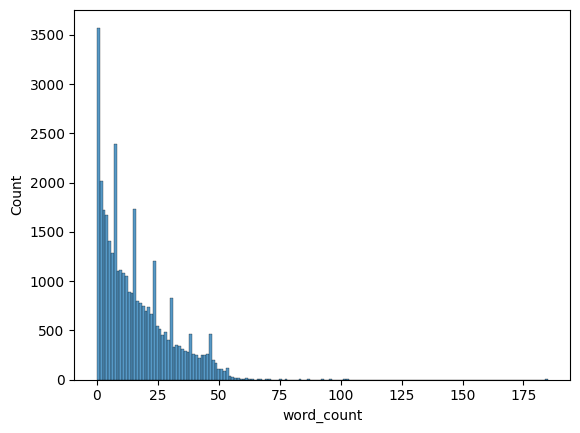

Number of Instances per Class: sentiment
Positive    18000
Negative    17982
Name: count, dtype: int64

Histogram of the distribution of classes


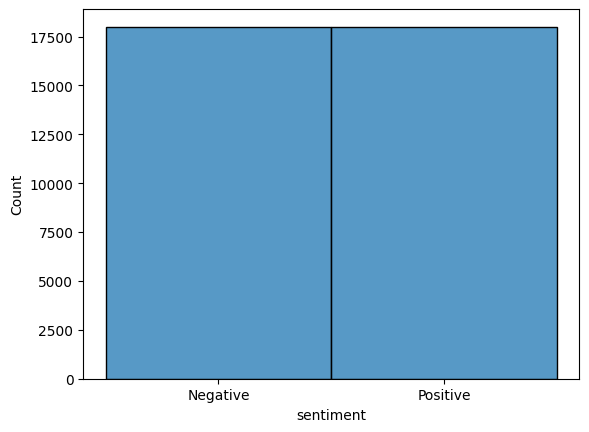


Pie Chart of the Distribution of Classes

Most frequent words


,Word,Frequency
0,ped,14327
1,entreg,9633
2,aplic,8427
3,bom,7152
4,pag,6439
5,pra,5437
6,vez,5297
7,compr,5295
8,cupom,4830
9,opç,4707



Most frequent words by class Negative

Most frequent words


,Word,Frequency
0,ped,10106
1,entreg,5710
2,aplic,5198
3,pag,4552
4,compr,3702
5,pra,3681
6,faz,3281
7,vez,3273
8,cupom,2818
9,cancel,2658



Most frequent words by class Positive

Most frequent words


,Word,Frequency
0,bom,5026
1,ped,4221
2,entreg,3923
3,aplic,3229
4,melhor,2473
5,ótim,2244
6,opç,2189
7,vez,2024
8,cupom,2012
9,pod,1985



WordCloud


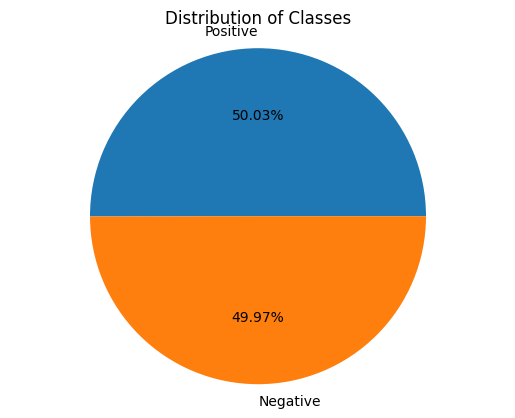

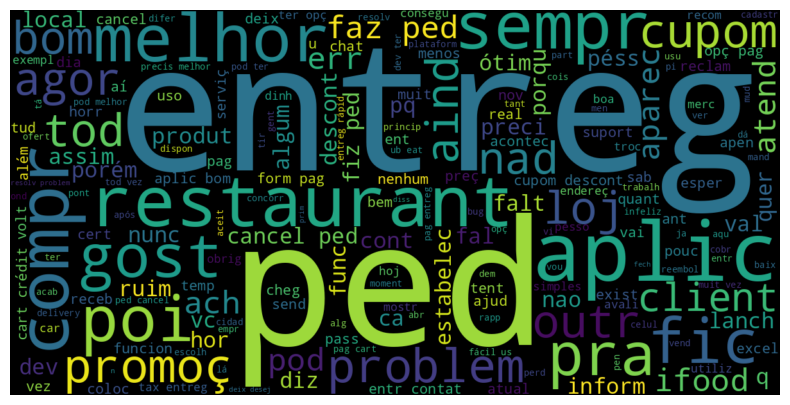

In [ ]:
data_analytics(df,'stemmed_text','sentiment')

In [ ]:
def join_tokens(tokens):
  return ' '.join(tokens)

df['text_clean'] = df['tokens_without_stopwords'].apply(join_tokens)

Number of nulls per column: Unnamed: 0                        0
reviewId                          0
userName                          0
userImage                         0
content                           0
score                             0
thumbsUpCount                     0
reviewCreatedVersion           3361
at                                0
replyContent                  27020
repliedAt                     27020
appVersion                     3361
sortOrder                         0
appId                             0
word_count                        0
removed_emoji                     0
removed_links                     0
tokens                            0
tokens_lowercase                  0
tokens_without_punctuation        0
tokens_without_stopwords          0
stemmed_text                      0
sentiment                         0
text_clean                        0
dtype: int64
The minimum number of words in the dataset is: 0
The maximum number of words in the dataset is:

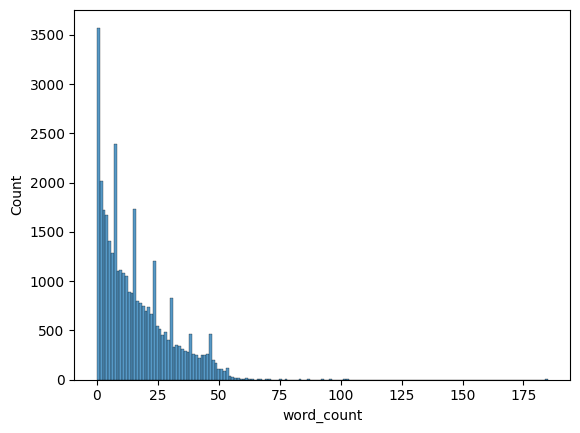

Number of Instances per Class: sentiment
Positive    18000
Negative    17982
Name: count, dtype: int64

Histogram of the distribution of classes


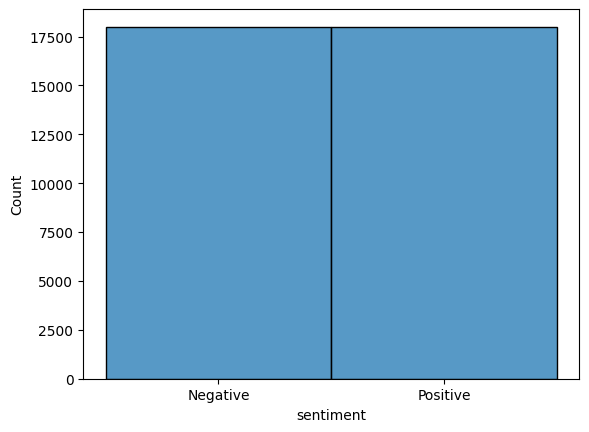


Pie Chart of the Distribution of Classes

Most frequent words


,Word,Frequency
0,pedido,9184
1,aplicativo,7816
2,bom,6754
3,pra,5350
4,entrega,5013
5,sempre,3402
6,vezes,3395
7,...,3258
8,opção,3188
9,pagamento,3061



Most frequent words by class Negative

Most frequent words


,Word,Frequency
0,pedido,6706
1,aplicativo,4825
2,pra,3655
3,entrega,2795
4,pagamento,2118
5,fazer,2104
6,...,2088
7,cartão,2008
8,bom,1986
9,vezes,1951



Most frequent words by class Positive

Most frequent words


,Word,Frequency
0,bom,4768
1,aplicativo,2991
2,pedido,2478
3,entrega,2218
4,bem,1746
5,pra,1695
6,sempre,1695
7,ótimo,1645
8,vezes,1444
9,cupons,1384



WordCloud


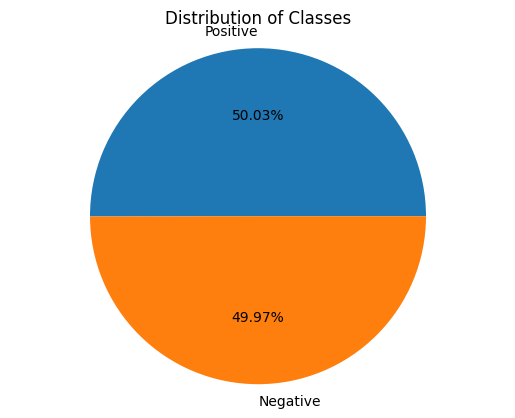

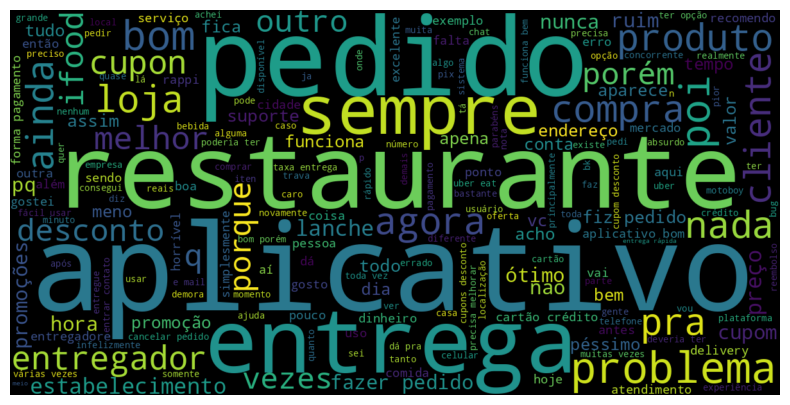

In [ ]:
data_analytics(df,'text_clean','sentiment')

In [ ]:
df = df[df['word_count'] > 0]
df

,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,...,word_count,removed_emoji,removed_links,tokens,tokens_lowercase,tokens_without_punctuation,tokens_without_stopwords,stemmed_text,sentiment,text_clean
0,0,2cf8d528-4be9-4582-8029-b12c7853ba9c,Daniela Aguilar,https://play-lh.googleusercontent.com/a-/ALV-U...,Fiz um pedido e veio com um item faltando. Ao ...,1,252,9.223.0,2023-09-09 02:48:00,NaN,...,41,Fiz um pedido e veio com um item faltando. Ao ...,Fiz um pedido e veio com um item faltando. Ao ...,"[Fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, um, pedido, e, veio, com, um, item, falt...","[fiz, pedido, veio, item, faltando, tentar, re...",fiz ped vei it falt tent report err aba `` aju...,Negative,fiz pedido veio item faltando tentar reportar ...
1,1,a0aefee6-4c2b-4d87-86d6-45ea111dcf50,Arlan Cruz (Miguelito),https://play-lh.googleusercontent.com/a-/ALV-U...,Informações do produto e imagens sem clareza. ...,1,173,9.223.0,2023-09-10 00:24:00,NaN,...,43,Informações do produto e imagens sem clareza. ...,Informações do produto e imagens sem clareza. ...,"[Informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl...","[informações, do, produto, e, imagens, sem, cl...","[informações, produto, imagens, clareza, lojas...",inform produt imag clar loj ag cancel ped conv...,Negative,informações produto imagens clareza lojas agem...
2,2,4b28558b-23e9-4e14-96b6-6e0e936f1ff1,Gabriel Liondas,https://play-lh.googleusercontent.com/a-/ALV-U...,"Uso o aplicativo a um bom tempo, porém, tive u...",1,12,9.222.1,2023-09-09 16:46:25,NaN,...,42,"Uso o aplicativo a um bom tempo, porém, tive u...","Uso o aplicativo a um bom tempo, porém, tive u...","[Uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, ,, por...","[uso, o, aplicativo, a, um, bom, tempo, porém,...","[uso, aplicativo, bom, tempo, porém, problema,...",uso aplic bom temp porém problem ped recent do...,Negative,uso aplicativo bom tempo porém problema pedido...
3,3,a7d610c9-30aa-4f8b-9a14-142ca9ec3b15,Ester Araújo,https://play-lh.googleusercontent.com/a-/ALV-U...,Não tem mais preocupação com qualidade. Os ent...,1,32,9.221.0,2023-08-31 21:14:46,NaN,...,25,Não tem mais preocupação com qualidade. Os ent...,Não tem mais preocupação com qualidade. Os ent...,"[Não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ...","[não, tem, mais, preocupação, com, qualidade, ...","[preocupação, qualidade, entregadores, atrasam...",preocup qual entreg atras demal entreg ped ain...,Negative,preocupação qualidade entregadores atrasam dem...
4,4,9c203cc4-289f-46cf-b55a-6332791b3b8c,Adr_Alv,https://play-lh.googleusercontent.com/a-/ALV-U...,"Não aparece mais cupons, a mais de 7 meses par...",1,14,9.222.1,2023-09-08 14:40:36,NaN,...,49,"Não aparece mais cupons, a mais de 7 meses par...","Não aparece mais cupons, a mais de 7 meses par...","[Não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, ,, a, mais, de, 7...","[não, aparece, mais, cupons, a, mais, de, 7, m...","[aparece, cupons, 7, meses, específico, restau...",aparec cupom 7 mes específ restaurant impõ pre...,Negative,aparece cupons 7 meses específico restaurantes...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35977,35977,785b13d8-ccc9-4629-b844-557f90d4d734,Lais De Lima,https://play-lh.googleusercontent.com/a/ACg8oc...,Muito bom amei esse app,5,0,10.0.0,2023-07-15 18:45:03,NaN,...,2,Muito bom amei esse app,Muito bom amei esse app,"[Muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]","[muito, bom, amei, esse, app]","[bom, amei]",bom ame,Positive,bom amei
35978,35978,c2121839-7857-49c9-9609-27aed288d297,Marta Silva,https://play-lh.googleusercontent.com/a-/ALV-U...,Muito bom,5,0,10.0.0,2023-07-15 15:56:29,NaN,...,1,Muito bom,Muito bom,"[Muito, bo

# Representing the data numerically

## Dividing the dataset into training and test sets.

In [ ]:
from sklearn.model_selection import train_test_split

seed = 42

x_train, x_test, y_train, y_test =  train_test_split(df['stemmed_text'], df['sentiment'], test_size = 0.3, stratify = df['sentiment'], random_state = 42)

## Bag of Words

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

bag_of_words = CountVectorizer()

x_train_num = bag_of_words.fit_transform(x_train)
x_test_num = bag_of_words.transform(x_test)

y_train_num = bag_of_words.transform(y_train)
y_test_num = bag_of_words.transform(y_test)

# Classification

## Training and prediction

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors = 5, metric = 'euclidean', n_jobs = -1)
knn.fit(x_train_num, y_train)

KNeighborsClassifier(metric='euclidean', n_jobs=-1)

In [ ]:
y_pred = knn.predict(x_test_num)
y_pred

array(['Positive', 'Positive', 'Negative', ..., 'Positive', 'Positive',
       'Negative'], dtype=object)

## Evaluating the model on the test set

### First Model

#### Checking the accuracy

In [ ]:
from sklearn.metrics import accuracy_score

accuracy_score(y_pred, y_test) * 100

72.65124059102314

#### Checking the confusion matrix

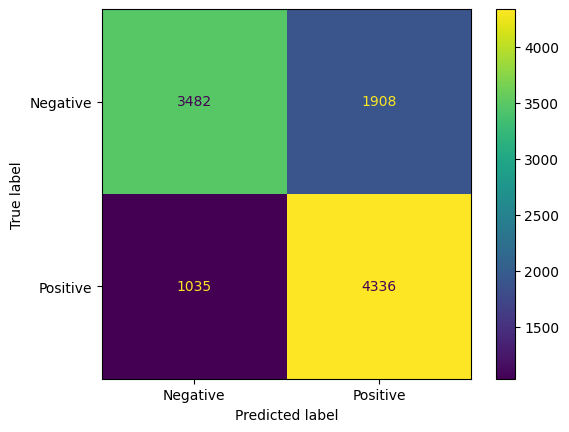

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

confusion = confusion_matrix(y_test, y_pred, labels = knn.classes_)
display_confusion = ConfusionMatrixDisplay(confusion_matrix = confusion, display_labels = knn.classes_)
display_confusion.plot();

### Final Model

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors = 20, metric = 'cosine', n_jobs = -1, weights = 'distance')
knn.fit(x_train_num, y_train)

KNeighborsClassifier(metric='cosine', n_jobs=-1, n_neighbors=20,
                     weights='distance')

In [ ]:
y_pred = knn.predict(x_test_num)
y_pred
accuracy_score(y_pred, y_test) * 100

80.327107146176

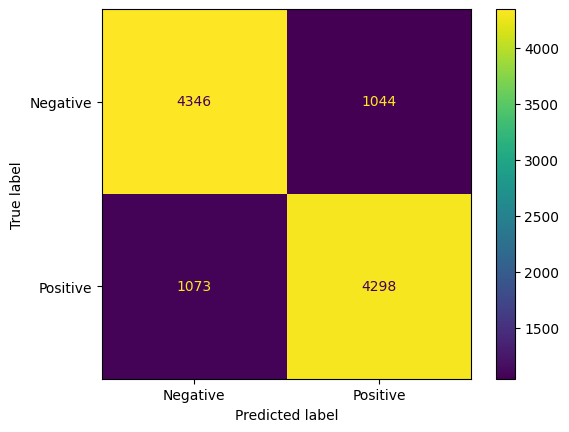

In [ ]:
confusion = confusion_matrix(y_test, y_pred, labels = knn.classes_)
display_confusion = ConfusionMatrixDisplay(confusion_matrix = confusion, display_labels = knn.classes_)
display_confusion.plot();

## Classifying new cases

In [ ]:
def classifierNewData(text):
  text = pre_processing(text)
  x = bag_of_words.transform([text])
  y = knn.predict(x)
  print(y)

### Manually generated cases

In [ ]:
classifierNewData("Aplicativo extremamente satisfatório. Além disso, a comida também é muito boa.")

['Positive']


In [ ]:
classifierNewData("Aplicativo extremamente satisfatório. Porém, a comida é muito ruim")

['Negative']


In [ ]:
classifierNewData("Tanto o aplicativo como a comida são ruins.")

['Negative']


In [ ]:
classifierNewData("Não sei o que achar, estava bem mediano o atendimento. Por um lado o lanche estava bom, mas a batata estava mole e sem sal")

['Positive']


In [ ]:
classifierNewData("Tudo perfeito, não tenho nada para reclamar")

['Positive']


In [ ]:
classifierNewData("Um pouco de atraso, mas o lanche compensou isso. Fantástico")

['Positive']


### Real cases

In [ ]:
classifierNewData("Surpreso com atendimento! Muito bom atendimento melhor que já tive de todos os McDonald's que frequentei")

['Positive']


In [ ]:
classifierNewData("Padrão Mac, tanto no local como no delivery, a entrega é bem rápida, em poucos minutos está com o pedido, sabor bom na minha opinião, principalmente o Quarteirão")

['Positive']


In [ ]:
classifierNewData("Horrível, sempre vem errado, não atende o telefone e não consigo contato nunca")

['Negative']


In [ ]:
classifierNewData("Fomos no domingo dia 25/06 e pegamos no drive thru porém o pedido demorou mais de 30 min para ficar pronto")

['Negative']


# Ensemble Machine Learning (Data Mining)


## Bagging

### Bagging - KNN

In [ ]:
from sklearn.ensemble import BaggingClassifier

In [ ]:
knn_bagging = KNeighborsClassifier(n_neighbors = 17, metric = 'cosine', n_jobs = -1, weights = 'distance')

In [ ]:
bagging_classifier = BaggingClassifier(estimator = knn_bagging,
                                       n_estimators = 10,
                                       max_samples = 0.8,
                                       bootstrap = True,
                                       bootstrap_features = True,
                                       n_jobs = -1)

In [ ]:
bagging_classifier.fit(x_train_num, y_train)

BaggingClassifier(bootstrap_features=True,
                  estimator=KNeighborsClassifier(metric='cosine', n_jobs=-1,
                                                 n_neighbors=17,
                                                 weights='distance'),
                  max_samples=0.8, n_jobs=-1)

In [ ]:
bagging_predict = bagging_classifier.predict(x_test_num)

In [ ]:
accuracy_bagging = accuracy_score(bagging_predict, y_test) * 100
accuracy_bagging

80.1877148963851

In [ ]:
estimadores_knn = bagging_classifier.estimators_

In [ ]:
for idx, knn_estimator in enumerate(estimadores_knn):
    print(f"Parâmetros do estimador KNN {idx + 1}:")
    print(knn_estimator.get_params())
    print("\n")

Parâmetros do estimador KNN 1:
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'cosine', 'metric_params': None, 'n_jobs': -1, 'n_neighbors': 17, 'p': 2, 'weights': 'distance'}


Parâmetros do estimador KNN 2:
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'cosine', 'metric_params': None, 'n_jobs': -1, 'n_neighbors': 17, 'p': 2, 'weights': 'distance'}


Parâmetros do estimador KNN 3:
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'cosine', 'metric_params': None, 'n_jobs': -1, 'n_neighbors': 17, 'p': 2, 'weights': 'distance'}


Parâmetros do estimador KNN 4:
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'cosine', 'metric_params': None, 'n_jobs': -1, 'n_neighbors': 17, 'p': 2, 'weights': 'distance'}


Parâmetros do estimador KNN 5:
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'cosine', 'metric_params': None, 'n_jobs': -1, 'n_neighbors': 17, 'p': 2, 'weights': 'distance'}


Parâmetros do estimador KNN 6:
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'cosine', 'metric_params'

### Bagging - MLP

In [ ]:
from sklearn.neural_network import MLPClassifier

In [ ]:
mlp_bagging = MLPClassifier(hidden_layer_sizes = (40,60),
                            activation = 'relu',
                            solver = 'adam',
                            max_iter = 45,
                            batch_size = 35,
                            learning_rate_init = 0.0001)
#------------------------------------------------------------------------------
bagging_mlp = BaggingClassifier(estimator = mlp_bagging,
                            n_estimators = 10,
                            max_samples = 0.8,
                            bootstrap = True,
                            bootstrap_features = True,
                            n_jobs = -1)

In [ ]:
bagging_mlp.fit(x_train_num, y_train)

BaggingClassifier(bootstrap_features=True,
                  estimator=MLPClassifier(batch_size=35,
                                          hidden_layer_sizes=(40, 60),
                                          learning_rate_init=0.0001,
                                          max_iter=45),
                  max_samples=0.8, n_jobs=-1)

In [ ]:
bagging_predict_mlp = bagging_mlp.predict(x_test_num)
accuracy_bagging_mlp = accuracy_score(bagging_predict_mlp, y_test) * 100
accuracy_bagging_mlp

82.06486386023603

### Bagging - SVM

In [ ]:
from sklearn.svm import SVC

In [ ]:
svm_bagging = SVC(kernel = 'linear',
                  C = 1.0,
                  gamma = 'scale')
#---------------------------------------------------------------------------
bagging_svm = BaggingClassifier(estimator = svm_bagging,
                                n_estimators = 10,
                                max_samples = 0.8,
                                bootstrap = True,
                                bootstrap_features = True,
                                n_jobs = -1)

In [ ]:
bagging_svm.fit(x_train_num, y_train)

BaggingClassifier(bootstrap_features=True, estimator=SVC(kernel='linear'),
                  max_samples=0.8, n_jobs=-1)

In [ ]:
bagging_predict_svm = bagging_svm.predict(x_test_num)
accuracy_bagging_svm = accuracy_score(bagging_predict_svm, y_test) * 100
accuracy_bagging_svm

79.0725768980578

## Voting
With three machine learning models: MLP, KNN and SVM

In [ ]:
from sklearn.ensemble import VotingClassifier

In [ ]:
mlp_voting = MLPClassifier(hidden_layer_sizes = (6,2),
                           activation = 'relu',
                           solver = 'adam',
                           batch_size = 9,
                           max_iter = 2,
                           learning_rate_init = 0.0001)
#---------------------------------------------------------------------------------
knn_voting = KNeighborsClassifier(n_neighbors = 6,
                                  metric = 'cosine',
                                  weights = 'distance',
                                  n_jobs = -1)
#---------------------------------------------------------------------------------
svm_voting = SVC(kernel = 'rbf',
                 C = 1.0,
                 gamma = 'scale')

In [ ]:
model_hard_voting = VotingClassifier([
    ('mlp', mlp_voting),
    ('svm', svm_voting),
    ('knn', knn_voting)],
    voting = 'hard')

In [ ]:
model_hard_voting.fit(x_train_num, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2) reached and the optimization hasn't converged yet.
  warnings.warn(


VotingClassifier(estimators=[('mlp',
                              MLPClassifier(batch_size=9,
                                            hidden_layer_sizes=(6, 2),
                                            learning_rate_init=0.0001,
                                            max_iter=2)),
                             ('svm', SVC()),
                             ('knn',
                              KNeighborsClassifier(metric='cosine', n_jobs=-1,
                                                   n_neighbors=6,
                                                   weights='distance'))])

In [ ]:
model_hard_voting_predict = model_hard_voting.predict(x_test_num)

In [ ]:
accuracy_hard_voting = accuracy_score(model_hard_voting_predict, y_test) * 100
accuracy_hard_voting

80.09478672985783